# Does the number of resistant strains change community recovery?

**One fixed synthetic community. Only resistance assignments change.**

We keep the same 57 strain identities, intrinsic growth rates, susceptibility parameters and equal initial abundances in every trial. We assign resistance to **0, 1, 5, 10, 20, 30, 40, or 57 strains**. A fixed nested assignment means raising the count adds carriers without removing the existing ones. Zero carriers is the all-sensitive baseline; 57 carriers is the all-resistant endpoint.

**Run:** Download this notebook, open in Jupyter, and select **Restart Kernel → Run All**. No model file or plotting script is required: an unchanged copy of the uploaded `updated_consumer_resource_model/resilience_model.py` is embedded below. Requires NumPy, pandas, SciPy, Matplotlib and IPython, as in the existing project environment. Images are already included for inspection before rerunning. CSV data and PNG figures are saved to `fixed_strains_resistance_results` beside the notebook.

## What does the stacked area graph mean?

At each time, strain *i* occupies a vertical thickness equal to its **absolute biomass Nᵢ(t)**. The stack height is total biomass **B(t) = Σ Nᵢ(t)**, and each strain's fraction of that height is **Nᵢ(t)/B(t)**. So the plot shows biomass and composition together. “Relative abundance” refers to vertical thickness at a given time, not the area integrated over time.

Yes, the simulation provides these absolute abundances directly. Observed relative sequencing abundances alone would require a separate measurement of total biomass to make this graph.

## Fair comparisons and limits

- Each strain's intrinsic growth rate and underlying IC50 stay fixed. A carrier pays the original model's growth cost, so its **effective** maximum growth rate changes when resistance is assigned.
- Every trial starts with the same total **0.005 OD**, split equally among 57 strains. More carriers means a greater resistant biomass fraction; this is a carrier-number/prevalence experiment, not an equal-resistant-biomass experiment.
- Each trial has an untreated control with **the same resistance assignment**, so the comparison includes the cost of carrying resistance.
- All carriers are immune to drug killing and have the same antibiotic degradation capacity per OD. No mutation, horizontal transfer or switching of carrier status occurs during a run.
- This is one fixed trait realization and one nested carrier order. It tests the chosen community; repeat with other carrier identities and trait seeds later to assess generalizability.


## 1. Settings and original model

The defaults use the original protocol: **0–4 h pregrowth → antibiotic at 4 h → 4–24 h treatment → 1:100 dilution into fresh drug-free medium at 24 h → 24–48 h recovery**. The no-carrier baseline receives the same antibiotic treatment.

At 24 h, both the sample **before dilution** and the state **after dilution** are retained. The area plots show the vertical drop rather than connecting the stages as though there were no transfer. At 0 h the biomass is small by design; the companion relative-composition figure makes the starting community visible.

In [1]:
from pathlib import Path
from dataclasses import replace
import types, sys, hashlib, json, colorsys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, to_hex
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
from IPython.display import display

TRAIT_SEED = 42
RESISTANT_COUNTS = [0, 1, 5, 10, 20, 30, 40, 57]
DOSE = 50.0  # µg/mL carbenicillin
OUT = Path('fixed_strains_resistance_results')
OUT.mkdir(exist_ok=True)
FIGURES = OUT / 'figures'
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({'font.size': 10, 'figure.dpi': 100,
                     'axes.spines.top': False, 'axes.spines.right': False})


In [2]:
ORIGINAL_MODEL_SOURCE = '"""\nPre-existing resistance and post-antibiotic community recovery\n==============================================================\n\nA minimal model of the barcoded E. coli community experiment: grow the community,\ntreat it with carbenicillin, dilute into fresh drug-free medium, let it recover, and\nmeasure how much of the community came back.\n\nEverything needed is in this one file:\n\n    BASELINE          every parameter, with units\n    run(**changes)    one matched experiment -> all readouts\n    sweep(...)        one parameter over a list of values\n    grid(...)         two parameters over a rectangle\n    check()           sanity checks; run once per session, not on import\n\nA notebook needs nothing but:\n\n    from resilience_model import run, sweep, grid, BASELINE, check\n    r = run(growth_mean=0.2)          # anything not named keeps its baseline value\n    r.metrics                         # one row of readouts\n    df = sweep("n_resistant", [0, 1, 2, 4, 8, 16])\n\nSee README.md for the assumptions, their justification, and the tested ranges.\n\nUnits: time in hours, biomass in OD, drug in ug/ml of carbenicillin.\n"""\nfrom __future__ import annotations\n\nfrom dataclasses import dataclass, field, replace\nfrom functools import lru_cache\nfrom pathlib import Path\nfrom typing import Any\n\nimport numpy as np\nimport pandas as pd\nfrom scipy.integrate import solve_ivp\n\n__all__ = ["BASELINE", "Params", "run", "sweep", "grid", "check", "Result",\n           "TESTED_RANGES", "SAMPLE_HOURS"]\n\nSAMPLE_HOURS = (4.0, 6.0, 24.0, 48.0)   # when the experiment samples\n\n\n# --------------------------------------------------------------------------- parameters\n@dataclass(frozen=True)\nclass Params:\n    """Every parameter of the model. `BASELINE` is the default instance.\n\n    Drug concentrations are in ug/ml of carbenicillin, so `dose` is the number the\n    protocol specifies and `km` is TEM-1\'s measured Michaelis constant in the same unit.\n    """\n    # --- community -------------------------------------------------------------\n    seed: int = 42                  # fixes every strain trait; change to test robustness\n    n_strains: int = 57             # barcoded library size\n    focal_index: int = 29           # k30, the strain that carries the resistance gene\n\n    # --- growth ----------------------------------------------------------------\n    growth_mean: float = 0.55       # 1/h, mean maximum growth rate across strains\n    growth_cv: float = 0.08         # strain-to-strain spread in maximum growth rate\n    food: float = 1.0               # OD-equivalents of nutrient in fresh medium\n    half_saturation: float = 0.05   # OD-equivalents; Monod constant for nutrient uptake\n    death_rate: float = 0.004       # 1/h, constant death rate (fed or starving)\n\n    # --- resistance ------------------------------------------------------------\n    n_resistant: int = 1            # how many strains carry the gene; 0 = sensitive community\n    focal_multiplier: float = 1.0   # starting biomass of k30 relative to the others (1x or 10x)\n    resistance_cost: float = 0.05   # fractional loss of maximum growth rate for a carrier\n\n    # --- antibiotic ------------------------------------------------------------\n    dose: float = 50.0              # ug/ml carbenicillin added at the start of treatment\n    gamma: float = 2.5              # max killing rate, as a multiple of the cell\'s current growth\n    hill: float = 2.0               # Hill coefficient of the killing response\n    susceptible_ic50: float = 5.0   # ug/ml, median IC50 of the susceptible strains\n    ic50_cv: float = 0.70           # strain-to-strain spread in IC50 (lognormal sd)\n    vmax: float = 10000.0           # ug/ml/h per OD of resistant biomass, at saturation\n    km: float = 5.3                 # ug/ml; TEM-1 Km for carbenicillin (14 uM)\n\n    # --- protocol --------------------------------------------------------------\n    initial_biomass: float = 0.005  # total OD at inoculation, split equally across strains\n    pregrowth_h: float = 4.0        # drug-free growth before treatment\n    treatment_h: float = 20.0       # with drug\n    dilution: float = 100.0         # fold dilution at transfer into fresh medium\n    recovery_h: float = 24.0        # drug-free growth after transfer\n\n    # --- measurement -----------------------------------------------------------\n    cells_per_OD: float = 1e9       # sets the extinction floor at one cell\n    detection_rel: float = 1e-4     # relative abundance below which a barcode is not counted\n\n    # --- numerics --------------------------------------------------------------\n    dt_out: float = 0.1             # output spacing, h (does not affect the solution)\n    rtol: float = 1e-8\n    atol: float = 1e-10\n\n    @property\n    def floor(self) -> float:\n        """Extinction threshold: one cell."""\n        return 1.0 / self.cells_per_OD\n\n\nBASELINE = Params()\n\n\n# --------------------------------------------------------------------------- community\n@lru_cache(maxsize=256)\ndef _traits(seed: int, n: int, growth_mean: float, growth_cv: float,\n            susceptible_ic50: float, ic50_cv: float):\n    """Per-strain maximum growth rate and IC50.\n\n    Strains differ in these two properties and nothing else: they are near-isogenic\n    single-gene deletions of one parent, competing for the same nutrient. Both draws\n    depend only on the seed, so changing any other parameter compares the same strains.\n    """\n    rng = np.random.default_rng(seed)\n    s = np.sqrt(np.log1p(growth_cv ** 2))\n    mu = growth_mean * np.exp(s * rng.standard_normal(n) - s ** 2 / 2)\n    ic50 = susceptible_ic50 * np.exp(ic50_cv * rng.standard_normal(n) - ic50_cv ** 2 / 2)\n    return mu, ic50\n\n\n@lru_cache(maxsize=256)\ndef _carriers(seed: int, n: int, focal_index: int, k: int):\n    """Which strains carry the resistance gene.\n\n    k30 is always first, then others in a fixed order from a dedicated random stream,\n    so the sets are nested: raising k adds carriers without reshuffling the existing\n    ones, and the draw never disturbs the trait sampling.\n    """\n    mask = np.zeros(n, bool)\n    if k <= 0:\n        return mask\n    others = np.array([i for i in range(n) if i != focal_index])\n    order = np.random.default_rng(seed + 991).permutation(others)\n    mask[np.r_[focal_index, order[:k - 1]].astype(int)] = True\n    return mask\n\n\ndef community(p: Params):\n    """Strain traits, carrier mask and starting biomass for one parameter set."""\n    mu, ic50 = _traits(p.seed, p.n_strains, p.growth_mean, p.growth_cv,\n                       p.susceptible_ic50, p.ic50_cv)\n    carrier = _carriers(p.seed, p.n_strains, p.focal_index, p.n_resistant)\n    mu = mu * (1 - p.resistance_cost * carrier)   # the enzyme is expressed constantly, so\n                                                  # its cost is a constant growth penalty\n    n0 = np.full(p.n_strains, p.initial_biomass / p.n_strains)\n    n0[p.focal_index] *= p.focal_multiplier\n    return mu, ic50, carrier, n0\n\n\n# --------------------------------------------------------------------------- dynamics\ndef _rates(N, R, a, mu, ic50, carrier, p: Params):\n    """Per-strain growth and killing, nutrient draw-down, and drug degradation."""\n    R = max(R, 0.0)\n    a = max(a, 0.0)\n    g = mu * R / (p.half_saturation + R)              # Monod growth on the shared nutrient\n    if a > 0.0:\n        x = (a / ic50) ** p.hill\n        kill = p.gamma * (x / (1.0 + x)) * g          # beta-lactam killing needs growth\n        kill = np.where(carrier, 0.0, kill)           # carriers are immune at these doses\n    else:\n        kill = np.zeros_like(g)\n    dR = -float(np.sum(N * g))                        # 1 OD of biomass consumes 1 unit of food\n    resistant_biomass = float(np.sum(N[carrier]))\n    da = -p.vmax * resistant_biomass * a / (p.km + a) # saturating degradation by live carriers\n    return g, kill, dR, da\n\n\ndef _segment(N0, R0, a0, t0, t1, mu, ic50, carrier, p: Params, alive):\n    """Integrate one phase, stopping whenever a strain crosses the one-cell floor.\n\n    Biomass is integrated in log space so that abundances spanning many orders of\n    magnitude stay accurate; a strain that reaches one cell is removed for good.\n    """\n    floor_log = np.log(p.floor)\n    grid_t = np.arange(t0, t1 + p.dt_out / 2, p.dt_out)\n    ts, Ns, Rs, as_, deaths = [], [], [], [], []\n    death_total = 0.0\n    N, R, a = N0.copy(), R0, a0\n\n    while t0 < t1 - 1e-12:\n        idx = np.flatnonzero(alive)\n        if idx.size == 0:\n            te = grid_t[(grid_t >= t0) & (grid_t <= t1)]\n            for t in te:\n                ts.append(t); Ns.append(N.copy()); Rs.append(R); as_.append(a)\n                deaths.append(death_total)\n            break\n\n        def rhs(t, y):\n            Nl = np.zeros_like(N)\n            Nl[idx] = np.exp(y[:idx.size])\n            g, kill, dR, da = _rates(Nl, y[-3], y[-2], mu, ic50, carrier, p)\n            dlog = g[idx] - p.death_rate - kill[idx]\n            dloss = float(np.sum(Nl * (p.death_rate + kill)))\n            return np.r_[dlog, dR, da, dloss]\n\n        def make_event(j):\n            def ev(t, y):\n                return y[j] - floor_log\n            ev.terminal = True\n            ev.direction = -1\n            return ev\n\n        y0 = np.r_[np.log(np.maximum(N[idx], p.floor * 1e-3)), R, a, death_total]\n        te = np.minimum(grid_t[(grid_t >= t0) & (grid_t <= t1)], t1)\n        sol = solve_ivp(rhs, (t0, t1), y0, method="LSODA", t_eval=te,\n                        events=[make_event(j) for j in range(idx.size)],\n                        rtol=p.rtol, atol=p.atol, dense_output=False)\n        if not sol.success:\n            raise RuntimeError(sol.message)\n\n        for k, t in enumerate(sol.t):\n            Nk = np.zeros_like(N)\n            Nk[idx] = np.exp(sol.y[:idx.size, k])\n            ts.append(float(t)); Ns.append(Nk); Rs.append(float(sol.y[-3, k]))\n            as_.append(float(sol.y[-2, k])); deaths.append(float(sol.y[-1, k]))\n\n        if sol.status == 1:                                  # a strain hit the floor\n            t0 = float(sol.t_events[[len(e) > 0 for e in sol.t_events].index(True)][0])\n            yend = np.concatenate([e for e in sol.y_events if len(e)])[0]\n            N = np.zeros_like(N); N[idx] = np.exp(yend[:idx.size])\n            R, a, death_total = float(yend[-3]), float(yend[-2]), float(yend[-1])\n            hit = idx[np.isclose(yend[:idx.size], floor_log, atol=1e-9)]\n            if hit.size == 0:\n                hit = idx[[int(np.argmin(yend[:idx.size]))]]\n            death_total += float(np.sum(N[hit]))             # the last cell is accounted for\n            alive[hit] = False\n            N[hit] = 0.0\n        else:\n            t0 = t1\n            N = Ns[-1].copy() if Ns else N\n            R, a, death_total = Rs[-1], as_[-1], deaths[-1]\n\n    return (np.array(ts), np.array(Ns), np.array(Rs), np.array(as_),\n            np.array(deaths), N, R, a, death_total)\n\n\ndef simulate(p: Params) -> dict:\n    """Pre-growth -> treatment -> 1:dilution transfer -> recovery."""\n    mu, ic50, carrier, n0 = community(p)\n    alive = n0 > p.floor\n    t_treat = p.pregrowth_h\n    t_transfer = p.pregrowth_h + p.treatment_h\n    t_end = t_transfer + p.recovery_h\n\n    T, NN, RR, AA, DD = [], [], [], [], []\n    removed = 0.0\n\n    # phase 1: drug-free pre-growth\n    ts, Ns, Rs, as_, dd, N, R, a, death = _segment(\n        n0, p.food, 0.0, 0.0, t_treat, mu, ic50, carrier, p, alive)\n    T += list(ts); NN += list(Ns); RR += list(Rs); AA += list(as_); DD += list(dd)\n\n    # phase 2: drug added\n    a = p.dose\n    ts, Ns, Rs, as_, dd, N, R, a, death2 = _segment(\n        N, R, a, t_treat, t_transfer, mu, ic50, carrier, p, alive)\n    T += list(ts); NN += list(Ns); RR += list(Rs); AA += list(as_)\n    DD += list(np.asarray(dd) + death)\n    death += death2\n\n    # transfer: 1:dilution into fresh drug-free medium\n    pre_transfer = N.copy()\n    removed += R          # the spent medium, with whatever nutrient is left in it, is discarded\n    N = N / p.dilution\n    removed += float(np.sum(pre_transfer) - np.sum(N))\n    gone = (N < p.floor) & alive\n    removed += float(np.sum(N[gone]))\n    N[gone] = 0.0\n    alive = alive & ~gone\n    post_transfer = N.copy()\n\n    # phase 3: recovery in fresh medium\n    ts, Ns, Rs, as_, dd, N, R, a, death3 = _segment(\n        N, p.food, 0.0, t_transfer, t_end, mu, ic50, carrier, p, alive)\n    T += list(ts); NN += list(Ns); RR += list(Rs); AA += list(as_)\n    DD += list(np.asarray(dd) + death)\n    death += death3\n\n    T = np.array(T); NN = np.array(NN)\n    # mass balance: food supplied = biomass standing + biomass dead + biomass discarded\n    supplied = p.food * 2 + float(np.sum(n0))      # fresh medium twice, plus the inoculum\n    standing = float(np.sum(NN[-1])) + float(RR[-1])\n    budget_error = standing + death + removed - supplied\n\n    return dict(params=p, t=T, N=NN, R=np.array(RR), a=np.array(AA),\n                carrier=carrier, mu=mu, ic50=ic50, t_transfer=t_transfer,\n                pre_transfer=pre_transfer, post_transfer=post_transfer,\n                budget_error=budget_error)\n\n\n# --------------------------------------------------------------------------- readouts\ndef snapshot(sim: dict, hour: float) -> np.ndarray:\n    """Absolute abundance of every strain at a sampling time.\n\n    The stored point at the transfer time is the end-of-treatment culture, i.e. the\n    24 h sample taken before the community is diluted.\n    """\n    t = sim["t"]\n    hit = np.flatnonzero(np.isclose(t, hour, atol=1e-7))\n    return sim["N"][hit[0] if hit.size else int(np.argmin(np.abs(t - hour)))]\n\n\ndef detected(x: np.ndarray, p: Params) -> np.ndarray:\n    """Abundances with strains below the sequencing detection limit set to zero."""\n    tot = x.sum()\n    if tot <= 0:\n        return np.zeros_like(x)\n    return np.where(x / tot >= p.detection_rel, x, 0.0)\n\n\ndef shannon(x: np.ndarray) -> float:\n    """H = -sum p ln p, as reported in the manuscript."""\n    s = x.sum()\n    if s <= 0:\n        return 0.0\n    q = x[x > 0] / s\n    return float(-(q * np.log(q)).sum())\n\n\ndef richness(x: np.ndarray) -> int:\n    return int((x > 0).sum())\n\n\ndef bray_curtis(x: np.ndarray, y: np.ndarray) -> float:\n    px = x / x.sum() if x.sum() > 0 else x\n    py = y / y.sum() if y.sum() > 0 else y\n    return float(np.abs(px - py).sum() / max((px + py).sum(), 1e-300))\n\n\n@dataclass\nclass Result:\n    """One matched experiment: resistant and sensitive communities, treated and not."""\n    params: Params\n    runs: dict[tuple[str, bool], dict]      # (community, treated) -> simulation\n    metrics: pd.Series                      # the readouts, one row\n    timeseries: pd.DataFrame                # per-strain abundance at the sampling hours\n    protection: pd.Series                   # per-strain protection score at 24 h\n\n    @property\n    def treated(self) -> dict:\n        return self.runs[("resistant", True)]\n\n    @property\n    def control(self) -> dict:\n        return self.runs[("resistant", False)]\n\n\ndef _metrics(runs, p: Params) -> pd.Series:\n    carrier = runs[("resistant", True)]["carrier"]\n    prot = ~carrier                                  # members without the gene\n\n    def at(key, hour):\n        return detected(snapshot(runs[key], hour), p)\n\n    t48 = {k: at(k, 48.0) for k in runs}\n    xt, xc = t48[("resistant", True)], t48[("resistant", False)]\n    st, sc = t48[("sensitive", True)], t48[("sensitive", False)]\n\n    def ratio(num, den):\n        return float(num / den) if den > 0 else np.nan\n\n    return pd.Series(dict(\n        # --- manuscript readouts, whole community --------------------------------\n        biomass_treated=float(xt.sum()), biomass_control=float(xc.sum()),\n        biomass_resilience=ratio(xt.sum(), xc.sum()),\n        shannon_treated=shannon(xt), shannon_control=shannon(xc),\n        shannon_resilience=ratio(shannon(xt), shannon(xc)),\n        richness_treated=richness(xt), richness_control=richness(xc),\n        compositional_resilience=1 - bray_curtis(xt, xc),\n        # --- the resistant member ------------------------------------------------\n        resistant_share=ratio(xt[carrier].sum(), xt.sum()),\n        resistant_biomass=float(xt[carrier].sum()),\n        n_resistant=int(carrier.sum()),\n        resistant_fraction=float(carrier.sum() / p.n_strains),\n        # --- the members the resistance is protecting ----------------------------\n        protected_shannon=shannon(xt[prot]), protected_shannon_control=shannon(xc[prot]),\n        protected_shannon_ratio=ratio(shannon(xt[prot]), shannon(xc[prot])),\n        protected_richness=richness(xt[prot]), protected_richness_control=richness(xc[prot]),\n        protected_biomass_ratio=ratio(xt[prot].sum(), xc[prot].sum()),\n        # --- the matched all-sensitive community ---------------------------------\n        sensitive_biomass_resilience=ratio(st.sum(), sc.sum()),\n        sensitive_shannon_treated=shannon(st), sensitive_shannon_control=shannon(sc),\n        sensitive_richness_treated=richness(st),\n        # --- diagnostics ---------------------------------------------------------\n        drug_at_24h=float(runs[("resistant", True)]["a"][\n            int(np.argmin(np.abs(runs[("resistant", True)]["t"] - 24.0)))]),\n        budget_error=max(abs(r["budget_error"]) for r in runs.values()),\n    ))\n\n\ndef _timeseries(runs, p: Params) -> pd.DataFrame:\n    rows = []\n    for (comm, trt), sim in runs.items():\n        for h in SAMPLE_HOURS:\n            x = snapshot(sim, h)\n            tot = x.sum()\n            for i in range(p.n_strains):\n                rows.append(dict(community=comm, treated=trt, hour=h, strain=f"k{i + 1:02d}",\n                                 carrier=bool(sim["carrier"][i]), absolute=float(x[i]),\n                                 relative=float(x[i] / tot) if tot > 0 else 0.0))\n    return pd.DataFrame(rows)\n\n\ndef _protection(runs, p: Params) -> pd.Series:\n    """log2[(treated/untreated with resistance) / (treated/untreated without)] at 24 h.\n\n    A one-cell pseudocount keeps strains that were removed from dividing by zero.\n    """\n    fl = p.floor\n\n    def x(key):\n        return snapshot(runs[key], 24.0) + fl\n\n    score = np.log2((x(("resistant", True)) / x(("resistant", False))) /\n                    (x(("sensitive", True)) / x(("sensitive", False))))\n    carrier = runs[("resistant", True)]["carrier"]\n    names = np.array([f"k{i + 1:02d}" for i in range(p.n_strains)])\n    return pd.Series(score[~carrier], index=names[~carrier], name="log2_protection")\n\n\n@lru_cache(maxsize=512)\ndef _cached_sim(p: Params) -> dict:\n    return simulate(p)\n\n\ndef run(params: Params | None = None, **changes: Any) -> Result:\n    """Run one matched experiment and return every readout.\n\n    Anything not named keeps its baseline value::\n\n        run()                       # the baseline experiment\n        run(growth_mean=0.2)        # slower community, everything else unchanged\n        run(dose=70, n_resistant=4)\n\n    The four runs are the manuscript\'s design: resistant and all-sensitive communities,\n    each treated and untreated. The untreated runs carry no drug, so they are cached and\n    reused across a sweep.\n    """\n    p = replace(params or BASELINE, **changes)\n    if p.n_resistant <= 0:\n        raise ValueError("n_resistant must be at least 1; the all-sensitive community "\n                         "is built automatically as the matched control")\n    sensitive = replace(p, n_resistant=0)\n    runs = {\n        ("resistant", True): _cached_sim(p),\n        ("resistant", False): _cached_sim(replace(p, dose=0.0)),\n        ("sensitive", True): _cached_sim(sensitive),\n        ("sensitive", False): _cached_sim(replace(sensitive, dose=0.0)),\n    }\n    return Result(params=p, runs=runs, metrics=_metrics(runs, p),\n                  timeseries=_timeseries(runs, p), protection=_protection(runs, p))\n\n\n# --------------------------------------------------------------------------- sweeps\ndef _row(changes: dict) -> pd.Series:\n    """One sweep row: the parameters that were changed, then every readout.\n\n    A changed parameter that is also a readout name (`n_resistant`, say) is kept only\n    once, so the row index stays unique.\n    """\n    r = run(**changes)\n    extra = pd.Series({"protection_median": float(r.protection.median()),\n                       "protection_min": float(r.protection.min()),\n                       "protection_max": float(r.protection.max())})\n    head = pd.Series({k: v for k, v in changes.items()\n                      if k not in r.metrics.index and k not in extra.index})\n    return pd.concat([head, r.metrics, extra])\n\n\ndef sweep(parameter: str, values, cache: str | None = None,\n          recompute: bool = False, **fixed: Any) -> pd.DataFrame:\n    """Vary one parameter over a list of values; everything else stays at baseline.\n\n        sweep("n_resistant", [1, 2, 4, 8, 16], vmax=500)\n\n    `cache` names a CSV: the sweep is computed once and reloaded afterwards. Delete the\n    file, or pass `recompute=True`, to run it again.\n    """\n    if cache and Path(cache).exists() and not recompute:\n        return pd.read_csv(cache)\n    df = pd.DataFrame([_row({parameter: v, **fixed}) for v in values])\n    if cache:\n        df.to_csv(cache, index=False)\n    return df\n\n\ndef grid(p1: str, v1, p2: str, v2, cache: str | None = None,\n         recompute: bool = False, **fixed: Any) -> pd.DataFrame:\n    """Vary two parameters over a rectangle, for a heatmap.\n\n        grid("gamma", [1, 2, 4], "vmax", [100, 1000], cache="panelC.csv")\n    """\n    if cache and Path(cache).exists() and not recompute:\n        return pd.read_csv(cache)\n    df = pd.DataFrame([_row({p1: a, p2: b, **fixed}) for a in v1 for b in v2])\n    if cache:\n        df.to_csv(cache, index=False)\n    return df\n\n\n# --------------------------------------------------------------------------- checks\nTESTED_RANGES = {\n    # parameter: (low, high) - the span over which the model has been exercised and\n    # behaves sensibly. Outside these the solver may struggle or the biology stops\n    # making sense; see README.md.\n    "growth_mean": (0.02, 1.8),\n    "growth_cv": (0.0, 0.6),\n    "food": (0.2, 5.0),\n    "half_saturation": (0.01, 0.5),\n    "death_rate": (0.0005, 0.02),\n    "n_resistant": (1, 57),\n    "focal_multiplier": (1.0, 30.0),\n    "resistance_cost": (0.0, 0.5),\n    "dose": (5.0, 500.0),\n    "gamma": (0.3, 30.0),\n    "hill": (1.0, 4.0),\n    "susceptible_ic50": (1.0, 20.0),\n    "ic50_cv": (0.1, 1.2),\n    "vmax": (10.0, 1e5),\n    "km": (0.5, 50.0),\n    "initial_biomass": (1e-4, 0.05),\n    "dilution": (10.0, 1000.0),\n}\n\n\ndef check(verbose: bool = True) -> pd.DataFrame:\n    """Sanity checks on the model\'s behaviour. Run once per session, not on import."""\n    rows = []\n\n    def add(name, ok, detail):\n        rows.append(dict(check=name, passed=bool(ok), detail=detail))\n\n    base = run()\n\n    # 1. mass balance\n    worst = base.metrics.budget_error\n    add("Mass balance closes: food supplied = biomass + dead + discarded",\n        worst < 1e-6, f"max |error| = {worst:.1e}")\n\n    # 2. no negative state\n    mn = min(min(r["N"].min(), r["R"].min(), r["a"].min()) for r in base.runs.values())\n    add("No negative biomass, nutrient or drug", mn > -1e-8, f"min = {mn:.1e}")\n\n    # 3. zero dose is the untreated control\n    z = run(dose=0.0)\n    d = float(np.max(np.abs(snapshot(z.treated, 48.0) - snapshot(z.control, 48.0))))\n    add("Dose 0 reproduces the untreated control exactly", d < 1e-12, f"max difference = {d:.1e}")\n\n    # 4. no resistance -> resistant and sensitive communities are identical\n    one = run(n_resistant=1, resistance_cost=0.0, vmax=0.0)\n    a1 = snapshot(one.runs[("resistant", True)], 48.0)\n    a2 = snapshot(one.runs[("sensitive", True)], 48.0)\n    d = float(np.max(np.abs(a1 - a2)))\n    add("A carrier that neither degrades nor pays a cost still differs only by its immunity",\n        a1[one.params.focal_index] >= a2[one.params.focal_index] - 1e-12,\n        f"max difference across strains = {d:.1e} (k30 immune, so it can only do better)")\n\n    # 5. killing needs growth\n    stat = run(pregrowth_h=40.0)\n    h = stat.params.pregrowth_h + stat.params.treatment_h\n    ratio = snapshot(stat.runs[("sensitive", True)], h).sum() / \\\n        snapshot(stat.runs[("sensitive", False)], h).sum()\n    add("A drug added in stationary phase kills almost nobody",\n        ratio > 0.95, f"treated/untreated biomass = {ratio:.4f}")\n\n    # 6. the transfer is an exact split\n    c = base.control\n    pre, post = c["pre_transfer"], c["post_transfer"]\n    keep = pre / base.params.dilution >= base.params.floor\n    add("The transfer is an exact 1:dilution split of the survivors",\n        np.allclose(post[keep], pre[keep] / base.params.dilution, rtol=1e-10) and\n        np.all(post[~keep] == 0.0),\n        f"1:{base.params.dilution:g}; {int((~keep).sum())} strains fell below one cell "\n        f"and were removed")\n\n    # 7. extinction is irreversible\n    bad = 0\n    for r in base.runs.values():\n        ever_zero = (r["N"] <= 0).any(axis=0)\n        for j in np.flatnonzero(ever_zero):\n            first = int(np.argmax(r["N"][:, j] <= 0))\n            if np.any(r["N"][first:, j] > 0):\n                bad += 1\n    add("A strain removed at the one-cell floor never returns", bad == 0,\n        f"{bad} strains reappeared")\n\n    # 8. carriers are immune\n    hard = run(dose=500.0, gamma=20.0, vmax=0.0)\n    x = snapshot(hard.treated, 48.0)\n    add("Resistant strains survive a dose that removes the susceptible ones",\n        x[hard.runs[("resistant", True)]["carrier"]].sum() > 0,\n        f"k30 biomass {x[hard.params.focal_index]:.3g} OD, "\n        f"susceptible richness {richness(detected(x, hard.params)) - 1}")\n\n    # 9. more resistant biomass clears the drug faster\n    slow = [run(n_resistant=k, vmax=20.0).metrics.drug_at_24h for k in (1, 8)]\n    add("More resistant biomass leaves less drug behind", slow[1] <= slow[0] + 1e-9,\n        f"drug at 24 h: 1 carrier {slow[0]:.3g}, 8 carriers {slow[1]:.3g} ug/ml")\n\n    # 10. saturating degradation makes clearance time scale with dose\n    # 10. degradation saturates: well above Km the removal rate stops tracking the dose.\n    # This is what keeps the dose dependence in the model; with first-order degradation\n    # the rate would be proportional to the dose and the two ratios below would match.\n    p0 = BASELINE\n    mu_, ic50_, carrier_, n0_ = community(p0)\n    N_ = np.where(carrier_, 0.01, 0.0)                 # a fixed amount of resistant biomass\n\n    def removal(a):\n        return -_rates(N_, p0.food, a, mu_, ic50_, carrier_, p0)[3]\n    hi = removal(10 * p0.km) / removal(5 * p0.km)      # both well above Km -> nearly flat\n    lo = removal(0.1 * p0.km) / removal(0.05 * p0.km)  # both well below Km -> nearly linear\n    add("Degradation saturates above Km and is first-order below it",\n        hi < 1.2 and lo > 1.8,\n        f"doubling the drug multiplies the removal rate by {hi:.2f} above Km "\n        f"and {lo:.2f} below it (first-order everywhere would give 2.00)")\n\n    # 11. resilience of an untreated run against itself is 1\n    add("Untreated against untreated gives resilience 1",\n        abs(1 - bray_curtis(snapshot(c, 48.0), snapshot(c, 48.0)) - 1.0) < 1e-12,\n        "compositional resilience = 1.000")\n\n    # 12. It is degradation that rescues the community, not the mere presence of a\n    # surviving resistant strain. A carrier that degrades nothing still competes for\n    # nutrient, which slows everyone\'s growth and therefore slows killing, so a small\n    # positive protection score remains. That residual must be far weaker than enzymatic\n    # degradation, and it must not rescue the susceptible members.\n    no_enz = run(vmax=0.0)\n    with_enz = base\n    add("Degradation, not the survival of a resistant strain, rescues the community",\n        float(with_enz.protection.median()) > 2 * float(no_enz.protection.median()) and\n        with_enz.metrics.protected_richness > no_enz.metrics.protected_richness + 10,\n        f"median protection {with_enz.protection.median():.1f} with the enzyme vs "\n        f"{no_enz.protection.median():.1f} without; susceptible survivors "\n        f"{with_enz.metrics.protected_richness:.0f} vs {no_enz.metrics.protected_richness:.0f} of 56")\n\n    # 13. Shannon cannot exceed ln(number of strains)\n    worstH = max(shannon(snapshot(r, 4.0)) for r in base.runs.values())\n    cap = np.log(base.params.n_strains)\n    add("Shannon diversity stays below ln(n_strains)", worstH <= cap + 1e-9,\n        f"max H = {worstH:.3f}, ln({base.params.n_strains}) = {cap:.3f}")\n\n    # 14. solver convergence\n    tight = run(rtol=1e-10, atol=1e-12)\n    rel = float(np.max(np.abs(snapshot(base.treated, 48.0) - snapshot(tight.treated, 48.0))) /\n                max(snapshot(tight.treated, 48.0).max(), 1e-300))\n    add("Tighter solver tolerances give the same answer", rel < 1e-4,\n        f"max relative difference = {rel:.1e}")\n\n    # 15. results are not an artefact of one seed\n    direction = [run(seed=s).metrics.protected_shannon_ratio >=\n                 run(seed=s, vmax=0.0).metrics.protected_shannon_ratio for s in (1, 7, 42, 99)]\n    add("Degradation helps the susceptible members for every seed tested",\n        all(direction), f"{sum(direction)}/4 seeds")\n\n    df = pd.DataFrame(rows)\n    if verbose:\n        with pd.option_context("display.width", 200, "display.max_colwidth", 95):\n            print(df.to_string(index=False))\n        print(f"\\n{int(df.passed.sum())}/{len(df)} checks passed")\n    return df\n\n\nif __name__ == "__main__":\n    check()\n'
EXPECTED_MODEL_SHA256 = 'a95f4c4c0490fbe35bced5985380cd43f4c38bffd0645a8d9976c700831cdeeb'
assert hashlib.sha256(ORIGINAL_MODEL_SOURCE.encode()).hexdigest() == EXPECTED_MODEL_SHA256
model = types.ModuleType('fixed_traits_original_resilience_model')
model.__file__ = 'embedded_original_resilience_model.py'
sys.modules[model.__name__] = model
exec(compile(ORIGINAL_MODEL_SOURCE, model.__file__, 'exec'), model.__dict__)
print('Loaded the unchanged original model. SHA-256:', EXPECTED_MODEL_SHA256)


Loaded the unchanged original model. SHA-256: a95f4c4c0490fbe35bced5985380cd43f4c38bffd0645a8d9976c700831cdeeb


In [3]:
# Original model checks, plus experiment-specific checks below.
model_checks = model.check(verbose=False)
display(model_checks)
if not model_checks.passed.all():
    raise RuntimeError('Review failed original-model checks before interpreting results.')

BASE = replace(model.BASELINE, seed=TRAIT_SEED, dose=DOSE, focal_multiplier=1.0)
assert BASE.n_strains == 57
assert len(set(RESISTANT_COUNTS)) == len(RESISTANT_COUNTS)
assert 0 in RESISTANT_COUNTS and all(0 <= k <= 57 for k in RESISTANT_COUNTS)
COUNTS = sorted(RESISTANT_COUNTS)
NAMES = [f'k{i:02d}' for i in range(1,58)]
T_ADD = BASE.pregrowth_h
T_TRANSFER = T_ADD + BASE.treatment_h
T_END = T_TRANSFER + BASE.recovery_h
STAGE_HOURS = [0., T_ADD, T_TRANSFER, T_END]
STAGE_LABELS = ['Initial', 'Antibiotic added', 'Before dilution', 'Recovery end']

# Reference traits are drawn once; no new trait randomization between trials.
reference_mu, reference_ic50, _, reference_n0 = model.community(replace(BASE, n_resistant=0))
traits = pd.DataFrame({'strain':NAMES, 'intrinsic_mu_per_h':reference_mu,
                       'susceptible_ic50_ug_ml':reference_ic50,
                       'initial_biomass_OD':reference_n0})
traits.to_csv(OUT/'fixed_strain_traits.csv', index=False)
display(traits.round(6))
print(f'Total initial biomass: {reference_n0.sum():.3f} OD; per strain: {reference_n0[0]:.7f} OD')
print('The IC50 column is each strain’s underlying susceptibility; carriers are modeled as immune.')


,check,passed,detail
0,Mass balance closes: food supplied = biomass +...,True,max |error| = 4.2e-08
1,"No negative biomass, nutrient or drug",True,min = -1.0e-10
2,Dose 0 reproduces the untreated control exactly,True,max difference = 0.0e+00
3,A carrier that neither degrades nor pays a cos...,True,max difference across strains = 9.4e-01 (k30 i...
4,A drug added in stationary phase kills almost ...,True,treated/untreated biomass = 1.0000
5,The transfer is an exact 1:dilution split of t...,True,1:100; 0 strains fell below one cell and were ...
6,A strain removed at the one-cell floor never r...,True,0 strains reappeared
7,Resistant strains survive a dose that removes ...,True,"k30 biomass 0.945 OD, susceptible richness 0"
8,More resistant biomass leaves less drug behind,True,"drug at 24 h: 1 carrier 0, 8 carriers 0 ug/ml"
9,Degradation saturates above Km and is first-or...,True,doubling the drug multiplies the removal rate ...


,strain,intrinsic_mu_per_h,susceptible_ic50_ug_ml,initial_biomass_OD
0,k01,0.561756,11.143951,0.000088
1,k02,0.504548,2.134764,0.000088
2,k03,0.582115,7.707800,0.000088
3,k04,0.591022,1.204939,0.000088
4,k05,0.469137,3.095713,0.000088
5,k06,0.494091,4.385769,0.000088
6,k07,0.553875,5.899063,0.000088
7,k08,0.534574,6.438506,0.000088
8,k09,0.547513,6.819465,0.000088
9,k10,0.512138,3.065867,0.000088


Total initial biomass: 0.005 OD; per strain: 0.0000877 OD
The IC50 column is each strain’s underlying susceptibility; carriers are modeled as immune.


## 2. Run the fixed community with different carrier counts

The model's convenience `run()` requires at least one carrier. To include a true **zero-carrier baseline**, this notebook calls the same original `simulate()` function directly for every condition, including zero. There is no alternative biological solver or changed equation.

Checks verify identical intrinsic traits, initial abundances, nested assignments, expected growth costs, nonnegative biomass and mass balance. Full trajectories, not just four sampling times, are retained.

In [4]:
runs = {}
audit_rows = []
assignment_rows = []
previous_mask = np.zeros(57, dtype=bool)

for k in COUNTS:
    p = replace(BASE, n_resistant=int(k))
    effective_mu, ic50, carrier, n0 = model.community(p)
    intrinsic, ic50_draw = model._traits(p.seed, p.n_strains, p.growth_mean,
                                        p.growth_cv, p.susceptible_ic50, p.ic50_cv)
    np.testing.assert_array_equal(intrinsic, reference_mu)
    np.testing.assert_array_equal(ic50, reference_ic50)
    np.testing.assert_array_equal(n0, reference_n0)
    np.testing.assert_allclose(effective_mu, reference_mu*(1-p.resistance_cost*carrier), rtol=1e-14)
    assert carrier.sum() == k and np.all(~previous_mask | carrier)
    previous_mask = carrier.copy()
    for treated in [False, True]:
        setting = p if treated else replace(p, dose=0.0)
        sim = model.simulate(setting)
        runs[(k, treated)] = sim
        assert np.isfinite(sim['N']).all() and sim['N'].min() >= 0
        assert np.diff(sim['t']).min() >= -1e-8
        assert abs(sim['budget_error']) < 1e-6
        np.testing.assert_allclose(sim['N'][0], reference_n0, rtol=1e-10)
        np.testing.assert_array_equal(sim['carrier'], carrier)
        expected_post = sim['pre_transfer']/setting.dilution
        expected_post[expected_post < setting.floor] = 0
        np.testing.assert_allclose(sim['post_transfer'], expected_post, atol=1e-15)
    audit_rows.append(dict(n_resistant=k, initial_biomass_OD=n0.sum(),
                           initial_resistant_share=n0[carrier].sum()/n0.sum(),
                           fixed_intrinsic_traits=True, fixed_initial_abundances=True,
                           nested_carriers=True, carrier_count_correct=True))
    for i, name in enumerate(NAMES):
        assignment_rows.append(dict(n_resistant=k, strain=name, carrier=bool(carrier[i]),
                                   intrinsic_mu_per_h=intrinsic[i], effective_mu_per_h=effective_mu[i],
                                   susceptible_ic50_ug_ml=ic50[i], initial_biomass_OD=n0[i]))
    print(f'{k:2d}/57 resistant strains: treated and matched untreated simulations complete')

audit = pd.DataFrame(audit_rows)
assignments = pd.DataFrame(assignment_rows)
audit.to_csv(OUT/'experiment_audit.csv', index=False)
assignments.to_csv(OUT/'strain_assignments_and_effective_traits.csv', index=False)
display(audit.round(4))


 0/57 resistant strains: treated and matched untreated simulations complete
 1/57 resistant strains: treated and matched untreated simulations complete
 5/57 resistant strains: treated and matched untreated simulations complete
10/57 resistant strains: treated and matched untreated simulations complete
20/57 resistant strains: treated and matched untreated simulations complete
30/57 resistant strains: treated and matched untreated simulations complete
40/57 resistant strains: treated and matched untreated simulations complete
57/57 resistant strains: treated and matched untreated simulations complete


,n_resistant,initial_biomass_OD,initial_resistant_share,fixed_intrinsic_traits,fixed_initial_abundances,nested_carriers,carrier_count_correct
0,0,0.005,0.0000,True,True,True,True
1,1,0.005,0.0175,True,True,True,True
2,5,0.005,0.0877,True,True,True,True
3,10,0.005,0.1754,True,True,True,True
4,20,0.005,0.3509,True,True,True,True
5,30,0.005,0.5263,True,True,True,True
6,40,0.005,0.7018,True,True,True,True
7,57,0.005,1.0000,True,True,True,True


## 3. See exactly which strains start resistant

Orange means carrier; gray means susceptible. Columns keep the same strain order in every row. All strains start equally abundant, so resistant biomass share at inoculation equals the fraction of strains carrying resistance. Assignments are fixed throughout each simulation.

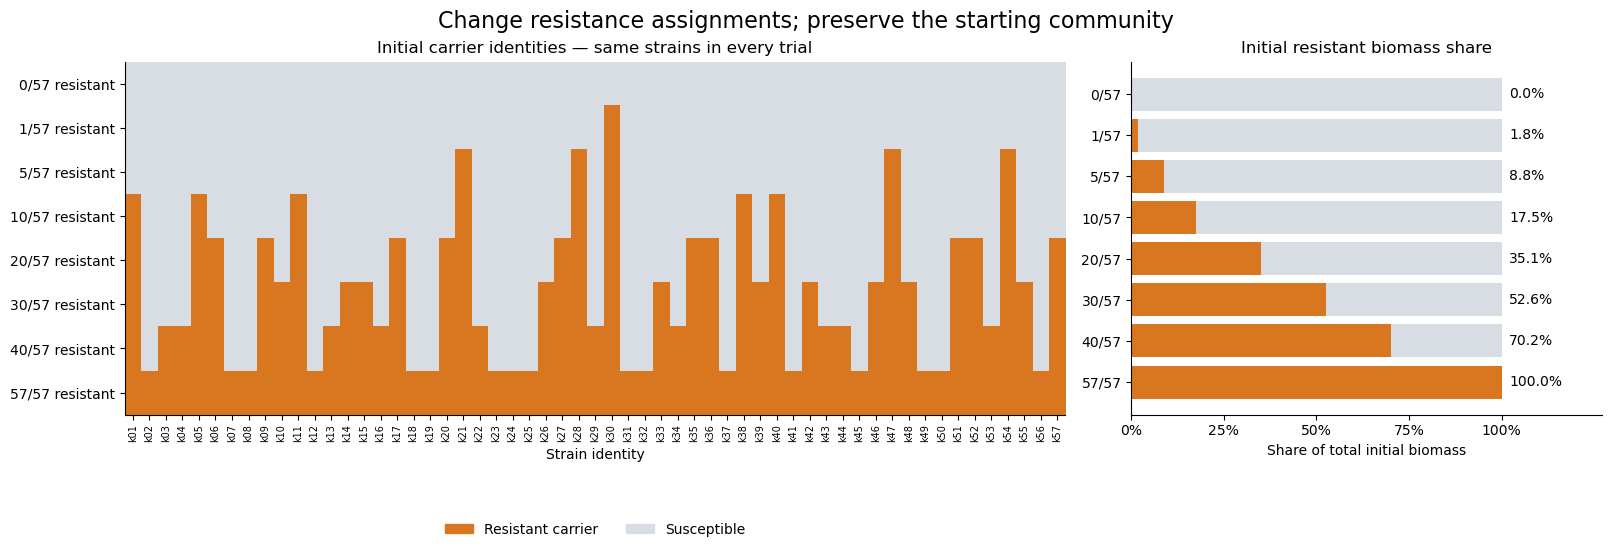

In [5]:
fig, axes = plt.subplots(1,2,figsize=(16,5.4),gridspec_kw={'width_ratios':[3,1.5]},layout='constrained')
masks = np.vstack([runs[(k,True)]['carrier'] for k in COUNTS])
axes[0].imshow(masks,aspect='auto',cmap=ListedColormap(['#d8dde3','#d97720']),vmin=0,vmax=1,interpolation='nearest')
axes[0].set_xticks(range(57), NAMES, rotation=90, fontsize=7)
axes[0].set_yticks(range(len(COUNTS)),[f'{k}/57 resistant' for k in COUNTS])
axes[0].set_title('Initial carrier identities — same strains in every trial')
axes[0].set_xlabel('Strain identity')
axes[0].legend(handles=[Patch(color='#d97720',label='Resistant carrier'),Patch(color='#d8dde3',label='Susceptible')],
               loc='upper center',bbox_to_anchor=(.5,-.27),ncol=2,frameon=False)
f = np.array(COUNTS)/57
axes[1].barh(range(len(COUNTS)),f,color='#d97720')
axes[1].barh(range(len(COUNTS)),1-f,left=f,color='#d8dde3')
axes[1].set_yticks(range(len(COUNTS)),[f'{k}/57' for k in COUNTS]);axes[1].invert_yaxis()
axes[1].set_xlim(0,1.27);axes[1].set_xticks([0,.25,.5,.75,1])
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
for i,v in enumerate(f): axes[1].text(1.02,i,f'{v:.1%}',va='center')
axes[1].set_title('Initial resistant biomass share')
axes[1].set_xlabel('Share of total initial biomass')
fig.suptitle('Change resistance assignments; preserve the starting community',fontsize=16)
fig.savefig(FIGURES/'01_initial_resistance.png',dpi=180,bbox_inches='tight')
plt.show(); plt.close(fig)


## 4. Biomass and strain composition over the entire experiment

**Each row is one resistance count.** Left: untreated. Right: antibiotic-treated. All panels use the same biomass scale and the same strain colors. The black line is total biomass.

Every colored band is one of the 57 strains; none are merged into an “other” category. Color represents strain identity, **not** resistance status (use the assignment map above for carrier status). With 57 bands, some colors and thin layers are hard to distinguish; exact values are exported for every strain.

The vertical line at 4 h marks antibiotic addition (or the matched time in controls). The line at 24 h marks 1:100 dilution into fresh medium, with no drug carryover. A narrow drop at 24 h is the imposed transfer, not antibiotic killing. The four major time points are labeled. A separate key below maps all colors to strains.

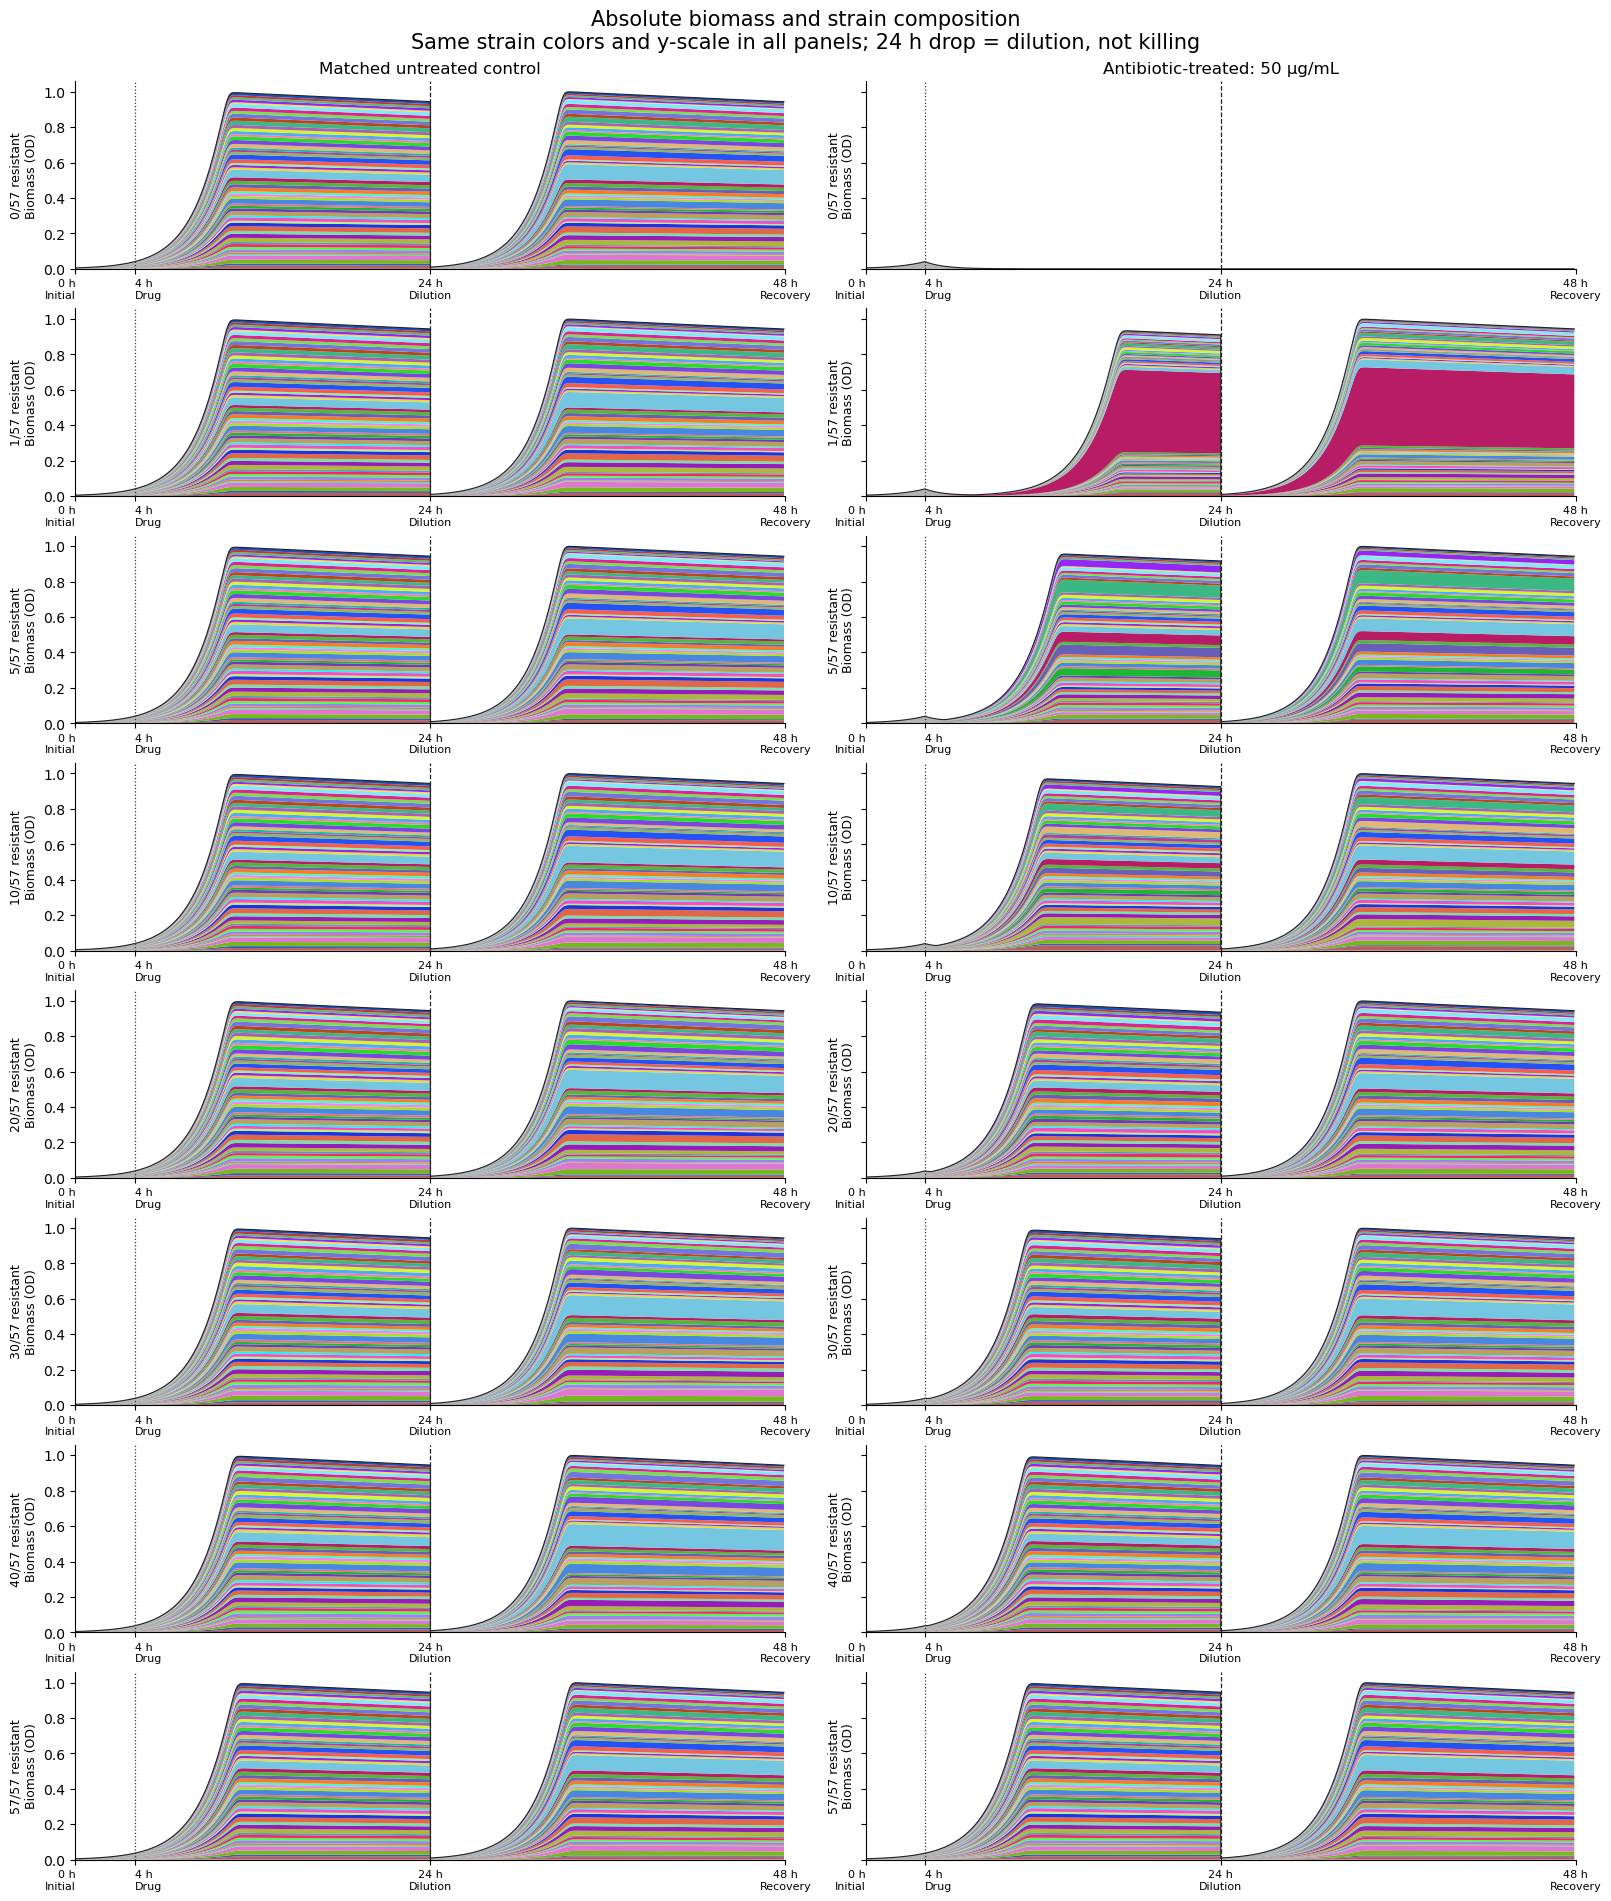

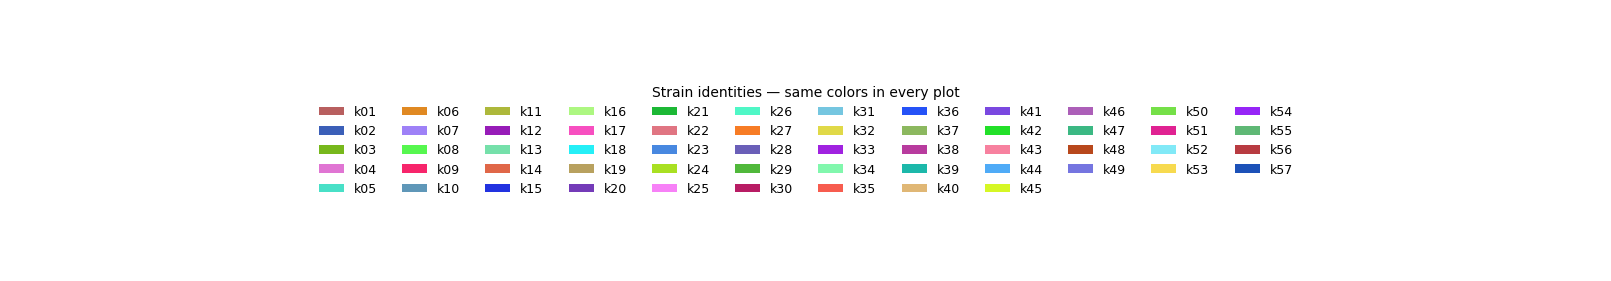

In [6]:
# A fixed color map for strain identity across all panels and figures.
STRAIN_COLORS = [colorsys.hsv_to_rgb((i*.61803398875)%1,
                   [.48,.68,.85][i%3], [.72,.88,.97][(i//3)%3]) for i in range(57)]
COLOR_HEX = [to_hex(c) for c in STRAIN_COLORS]
traits.assign(plot_color_hex=COLOR_HEX).to_csv(OUT/'fixed_strain_traits.csv',index=False)

def plot_stacked_trajectories(relative=False):
    fig, axes = plt.subplots(len(COUNTS),2,figsize=(16,2.2*len(COUNTS)+1.3),
                              sharex=True,sharey=True,squeeze=False,layout='constrained')
    max_total = max(s['N'].sum(axis=1).max() for s in runs.values())
    for row,k in enumerate(COUNTS):
        for col,treated in enumerate([False,True]):
            ax=axes[row,col];sim=runs[(k,treated)]
            t=np.maximum.accumulate(sim['t']) # preserve the pre/post-transfer jump at repeated times
            biomass=sim['N'].sum(axis=1)
            if relative:
                values=np.divide(sim['N'],biomass[:,None],out=np.zeros_like(sim['N']),where=biomass[:,None]>0)
            else:
                values=sim['N']
            ax.stackplot(t,values.T,colors=STRAIN_COLORS,linewidth=0)
            if not relative:
                ax.plot(t,biomass,color='#222222',lw=.8)
            # Extinction gives undefined composition; mark rather than imply 0% composition.
            if relative and (biomass<=0).any():
                ax.fill_between(t,0,1,where=biomass<=0,color='#eeeeee',hatch='xx',step='mid')
            ax.axvline(T_ADD,color='#333333',ls=':',lw=.9)
            ax.axvline(T_TRANSFER,color='#222222',ls='--',lw=.9)
            ax.set_xticks(STAGE_HOURS, [f'{T_ADD*0:g} h\nInitial', f'{T_ADD:g} h\nDrug', f'{T_TRANSFER:g} h\nDilution', f'{T_END:g} h\nRecovery'], fontsize=8)
            ax.tick_params(labelbottom=True)
            ax.get_xticklabels()[0].set_ha('right')
            ax.get_xticklabels()[1].set_ha('left')
            ax.set_xlim(0,T_END)
            ax.set_ylim(0,1.02 if relative else max_total*1.06)
            ax.set_ylabel(f'{k}/57 resistant\n'+('Fraction' if relative else 'Biomass (OD)'),fontsize=9)
            if relative: ax.yaxis.set_major_formatter(PercentFormatter(1))
            if row==0: ax.set_title('Matched untreated control' if not treated else f'Antibiotic-treated: {DOSE:g} µg/mL')
    title='Relative strain composition' if relative else 'Absolute biomass and strain composition'
    fig.suptitle(title+'\nSame strain colors and y-scale in all panels; 24 h drop = dilution, not killing',fontsize=15)
    name='03_relative_composition' if relative else '02_absolute_biomass_composition'
    fig.savefig(FIGURES/(name+'.png'),dpi=180,bbox_inches='tight')
    plt.show();plt.close(fig)

plot_stacked_trajectories(relative=False)

# Standalone color key makes the large area figure easier to read.
fig,ax=plt.subplots(figsize=(16,2.7),layout='constrained');ax.axis('off')
ax.legend(handles=[Patch(facecolor=c,label=s) for s,c in zip(NAMES,STRAIN_COLORS)],
          loc='center',ncol=12,frameon=False,fontsize=9, title='Strain identities — same colors in every plot')
fig.savefig(FIGURES/'strain_color_key.png',dpi=180,bbox_inches='tight')
plt.show();plt.close(fig)


## 5. Relative composition companion

This is the same set of trajectories, normalized to 100% at each nonempty time point. Use this figure to inspect composition when total biomass is too small to see in the absolute plot, especially at inoculation and immediately after dilution. Proportional dilution alone does not change relative composition unless some strains cross the model's extinction floor.

Gray cross-hatched intervals indicate zero total biomass, where relative composition is undefined.

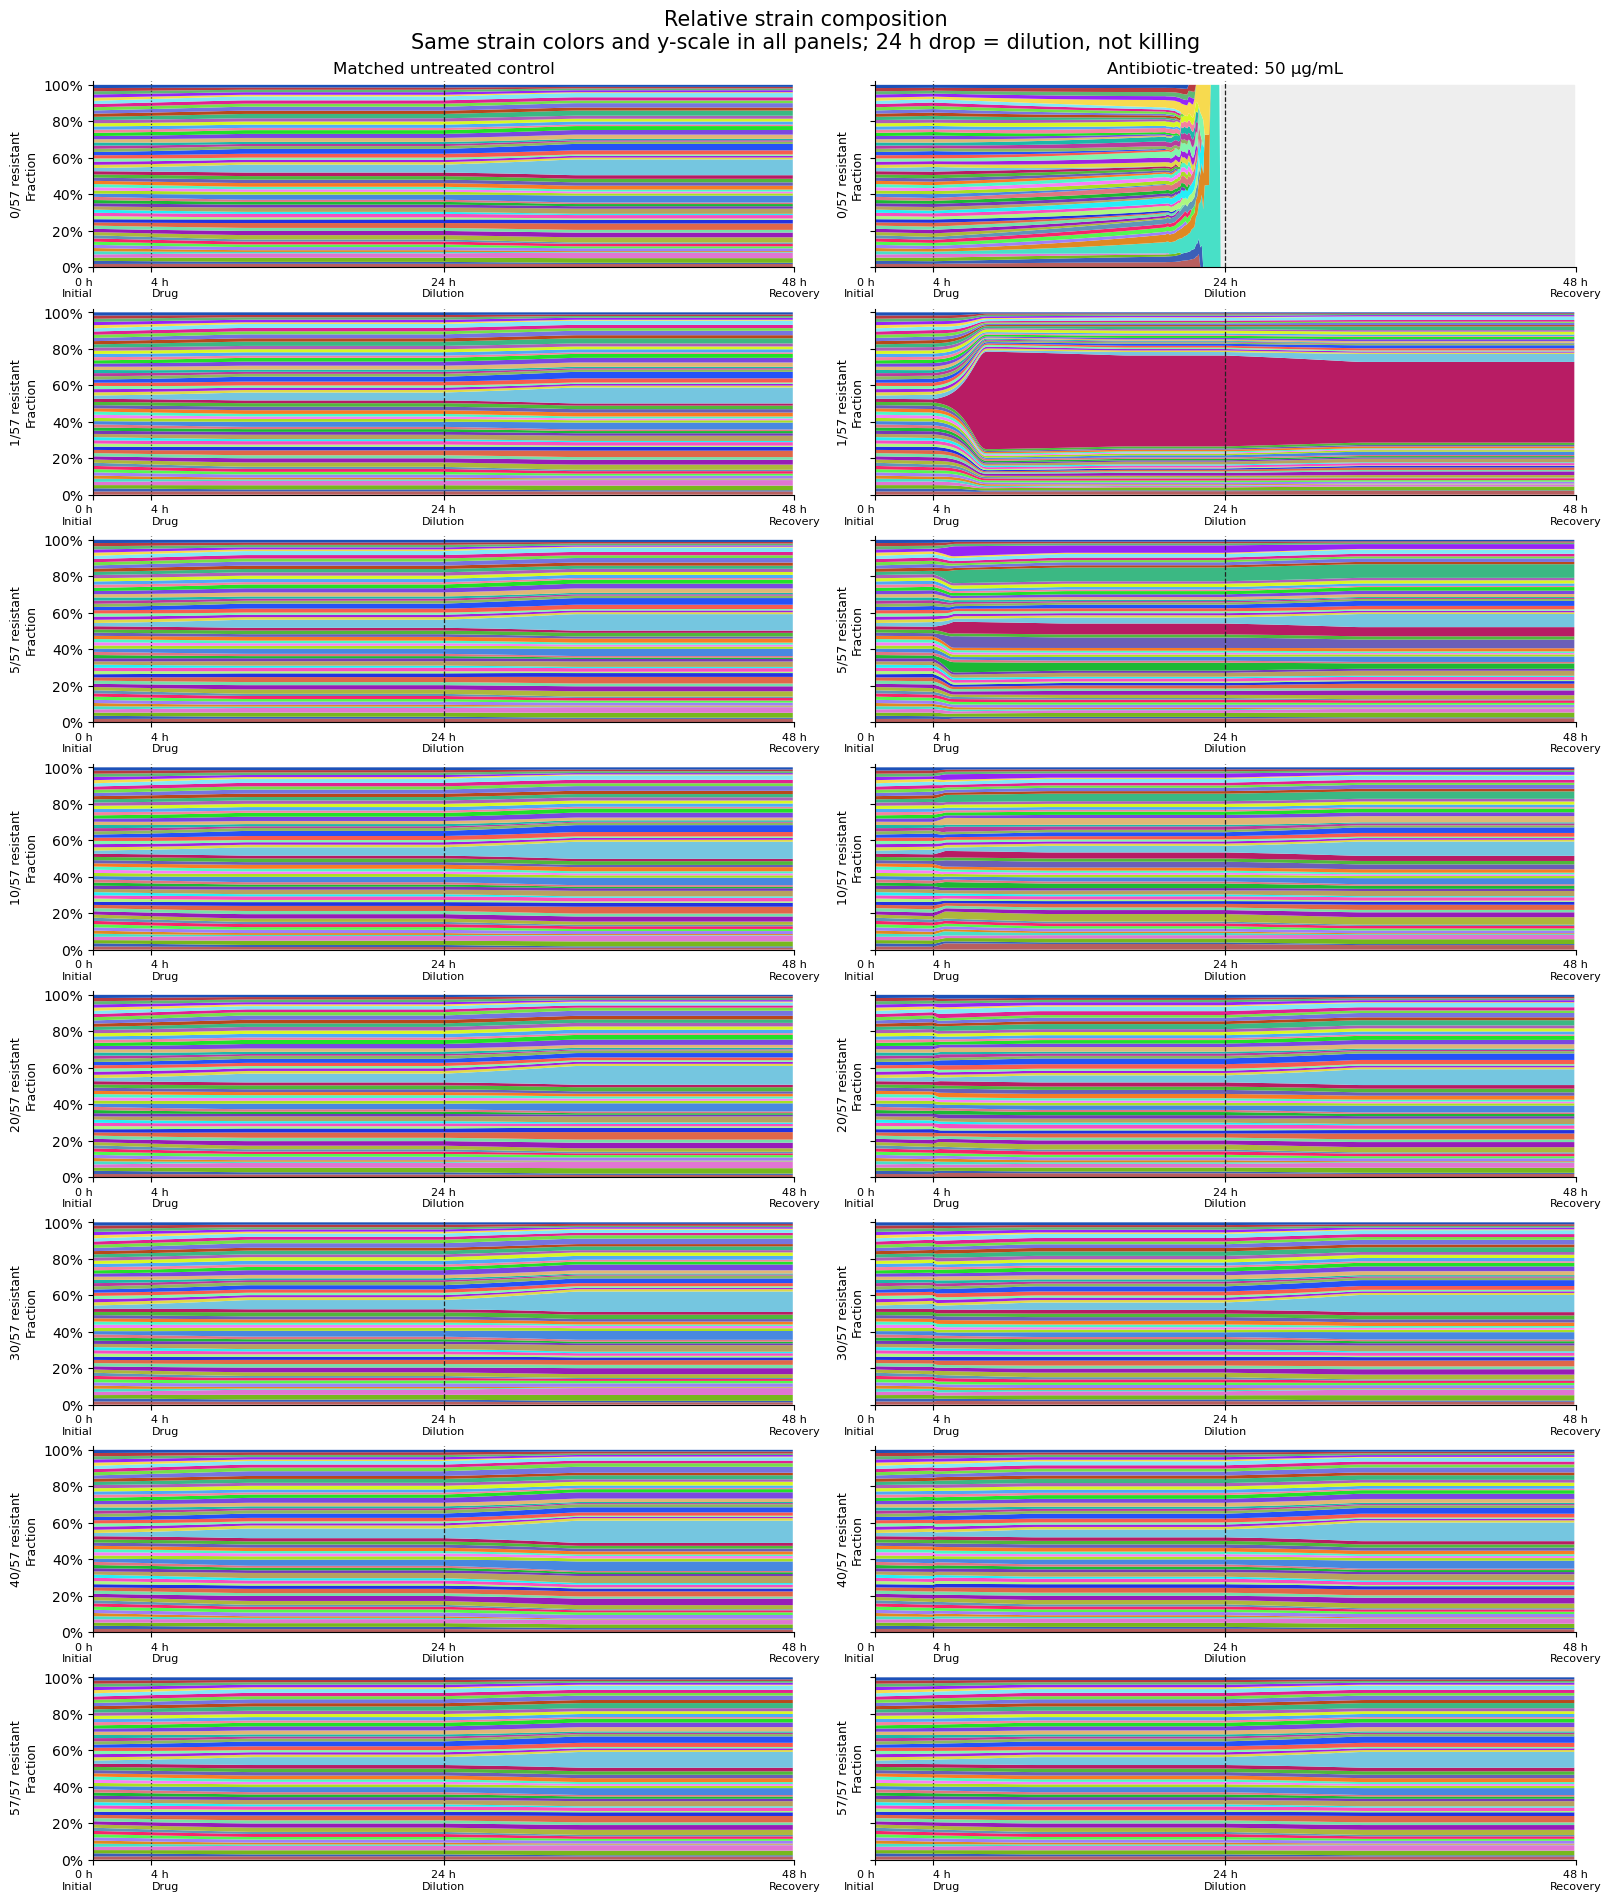

In [7]:
plot_stacked_trajectories(relative=True)

## 6. Shannon diversity, resistant share, and community-level dynamics

Shannon diversity uses all positive absolute abundances: **H = −Σ pᵢ ln(pᵢ)**. The initial value is ln(57) ≈ 4.04 because all strains start equally abundant. It is undefined if total biomass is zero. It can change through evenness as well as extinction; biomass recovery alone does not guarantee diversity recovery.

These summaries use one color per **carrier count**, not per strain. Solid lines are treated; dashed lines are matched untreated controls. The bottom-right panel shows drug clearance in treated communities.

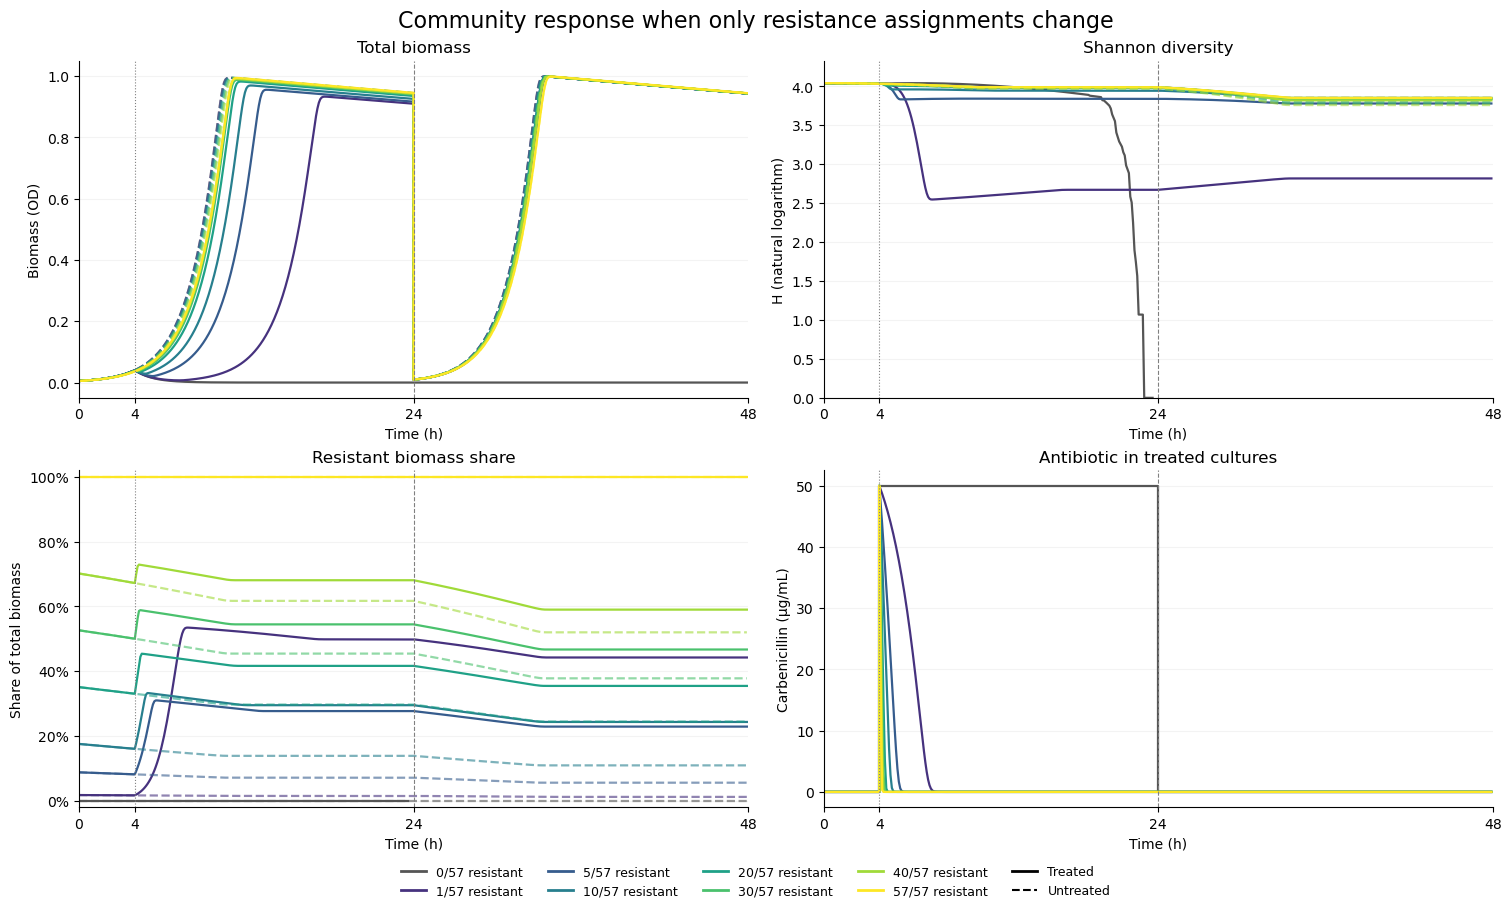

In [8]:
COUNT_COLORS = {k:plt.get_cmap('viridis')(i/max(len(COUNTS)-1,1)) for i,k in enumerate(COUNTS)}
COUNT_COLORS[0] = '#555555'

def community_series(sim):
    x=sim['N'];b=x.sum(axis=1)
    p=np.divide(x,b[:,None],out=np.zeros_like(x),where=b[:,None]>0)
    logp=np.zeros_like(p);np.log(p,out=logp,where=p>0)
    H=-(p*logp).sum(axis=1);H[b<=0]=np.nan
    resistant=np.divide(x[:,sim['carrier']].sum(axis=1),b,
                         out=np.full_like(b,np.nan),where=b>0)
    return b,H,resistant

fig,axes=plt.subplots(2,2,figsize=(15,9),layout='constrained')
for k in COUNTS:
    for treated in [False,True]:
        sim=runs[(k,treated)];b,H,r=community_series(sim)
        for ax,v in zip(axes.flat,[b,H,r,sim['a']]):
            if ax is axes[1,1] and not treated: continue
            ax.plot(np.maximum.accumulate(sim['t']),v,color=COUNT_COLORS[k],
                    ls='-' if treated else '--',lw=1.6,alpha=1 if treated else .6)
for ax,title,ylabel in zip(axes.flat,['Total biomass','Shannon diversity','Resistant biomass share','Antibiotic in treated cultures'],
                          ['Biomass (OD)','H (natural logarithm)','Share of total biomass','Carbenicillin (µg/mL)']):
    ax.axvline(T_ADD,color='gray',ls=':',lw=.8);ax.axvline(T_TRANSFER,color='gray',ls='--',lw=.8)
    ax.set(title=title,ylabel=ylabel,xlabel='Time (h)',xlim=(0,T_END))
    ax.set_xticks(STAGE_HOURS);ax.grid(axis='y',alpha=.15)
axes[0,1].set_ylim(0,np.log(57)*1.07)
axes[1,0].set_ylim(-.02,1.02);axes[1,0].yaxis.set_major_formatter(PercentFormatter(1))
handles=[plt.Line2D([0],[0],color=COUNT_COLORS[k],lw=2,label=f'{k}/57 resistant') for k in COUNTS]
handles += [plt.Line2D([0],[0],color='black',lw=2,label='Treated'),
            plt.Line2D([0],[0],color='black',ls='--',label='Untreated')]
fig.legend(handles=handles,loc='outside lower center',ncol=5,frameon=False,fontsize=9)
fig.suptitle('Community response when only resistance assignments change',fontsize=16)
fig.savefig(FIGURES/'04_community_dynamics.png',dpi=180,bbox_inches='tight')
plt.show();plt.close(fig)


## 7. Quantify recovery against each matched untreated community

The endpoint table reports the antibiotic response after regrowth. A biomass ratio of 1 means equal biomass to the matched untreated culture. A Shannon difference of 0 means equal diversity. Composition similarity is **1 − Bray–Curtis dissimilarity of relative profiles**; 1 means identical composition.

“Detected” means positive biomass and relative abundance ≥ the original model's detection threshold. Reported Shannon uses all positive abundances instead, to distinguish diversity from the detection rule. Susceptible strain retention is the fraction of the initially susceptible strain identities still detected at the endpoint; it is undefined for the all-resistant trial. Not detected does not necessarily mean extinct.

No single metric determines the best recovery: a resistant-dominated community can regain total biomass while differing strongly in composition from its control.

,n_resistant,initial_resistant_share,biomass_treated_48h,biomass_control_48h,biomass_ratio_to_control,shannon_treated_48h,shannon_control_48h,shannon_difference,composition_similarity_to_control,composition_similarity_to_initial,resistant_share_48h,detected_strains_48h,susceptible_detected_48h,susceptible_strain_retention
0,0,0.0000,0.0000,0.9433,0.0000,NaN,3.8533,NaN,NaN,NaN,NaN,0,0,0.0
1,1,0.0175,0.9439,0.9433,1.0006,2.8185,3.8506,-1.0320,0.5666,0.5318,0.4424,57,56,1.0
2,5,0.0877,0.9436,0.9434,1.0003,3.7812,3.8401,-0.0589,0.8217,0.7228,0.2289,57,52,1.0
3,10,0.1754,0.9437,0.9435,1.0002,3.8444,3.8299,0.0144,0.8654,0.7510,0.2433,57,47,1.0
4,20,0.3509,0.9438,0.9437,1.0002,3.8533,3.8093,0.0440,0.8899,0.7665,0.3546,57,37,1.0
5,30,0.5263,0.9440,0.9438,1.0002,3.8399,3.7851,0.0548,0.9110,0.7659,0.4670,57,27,1.0
6,40,0.7018,0.9441,0.9440,1.0002,3.8209,3.7608,0.0601,0.9299,0.7610,0.5902,57,17,1.0
7,57,1.0000,0.9447,0.9447,1.0000,3.8533,3.8533,-0.0000,1.0000,0.7665,1.0000,57,0,NaN


Detection threshold: 0.0001 relative abundance (0.01%).


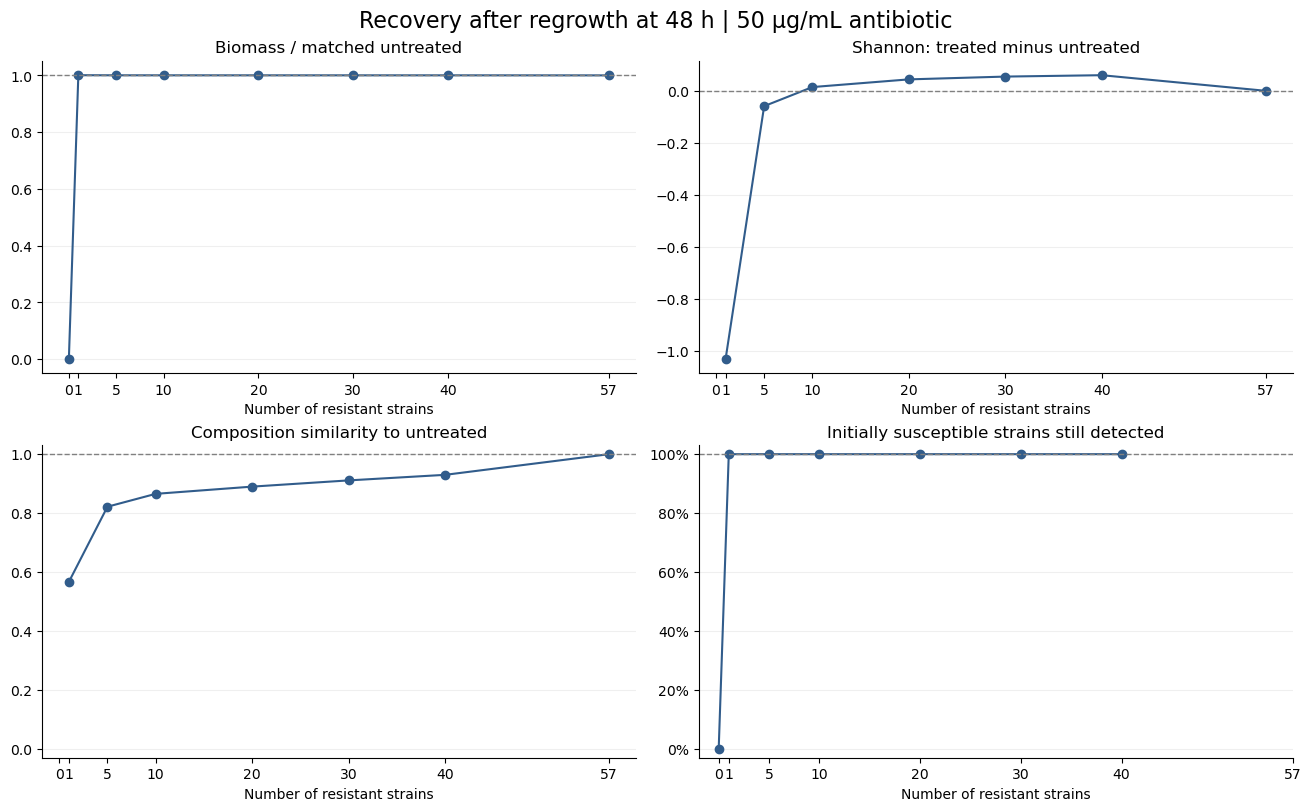

In [9]:
def snapshot(sim,hour):
    # The original snapshot selects the pre-dilution state at the transfer time.
    return model.snapshot(sim,hour)

def profile_metrics(x,carrier):
    b=float(x.sum())
    if b<=0:
        return dict(biomass=0.,shannon=np.nan,resistant_share=np.nan,detected=0,
                    susceptible_detected=0,resistant_detected=0)
    p=x/b
    detected=(p>=BASE.detection_rel)&(x>0)
    return dict(biomass=b,shannon=float(-(p[p>0]*np.log(p[p>0])).sum()),
                resistant_share=float(x[carrier].sum()/b),detected=int(detected.sum()),
                susceptible_detected=int((detected&~carrier).sum()),
                resistant_detected=int((detected&carrier).sum()))

def ratio(a,b): return a/b if b>0 and np.isfinite(b) else np.nan

def composition_similarity(x,y):
    if x.sum()<=0 or y.sum()<=0:return np.nan
    return float(1-.5*np.abs(x/x.sum()-y/y.sum()).sum())

stage_rows=[];endpoint_rows=[]
for k in COUNTS:
    for treated in [False,True]:
        sim=runs[(k,treated)]
        for hour,stage in zip(STAGE_HOURS,STAGE_LABELS):
            stage_rows.append(dict(n_resistant=k,treated=treated,hour=hour,stage=stage,
                                  **profile_metrics(snapshot(sim,hour),sim['carrier'])))
        stage_rows.append(dict(n_resistant=k,treated=treated,hour=T_TRANSFER,stage='Immediately after dilution',
                              **profile_metrics(sim['post_transfer'],sim['carrier'])))
    t=runs[(k,True)];c=runs[(k,False)]
    xt=snapshot(t,T_END);xc=snapshot(c,T_END)
    mt=profile_metrics(xt,t['carrier']);mc=profile_metrics(xc,c['carrier'])
    endpoint_rows.append(dict(n_resistant=k,initial_resistant_share=k/57,
        biomass_treated_48h=mt['biomass'],biomass_control_48h=mc['biomass'],
        biomass_ratio_to_control=ratio(mt['biomass'],mc['biomass']),
        shannon_treated_48h=mt['shannon'],shannon_control_48h=mc['shannon'],
        shannon_difference=mt['shannon']-mc['shannon'],
        composition_similarity_to_control=composition_similarity(xt,xc),
        composition_similarity_to_initial=composition_similarity(xt,reference_n0),
        resistant_share_48h=mt['resistant_share'],detected_strains_48h=mt['detected'],
        susceptible_detected_48h=mt['susceptible_detected'],
        susceptible_strain_retention=ratio(mt['susceptible_detected'],57-k)))
stages=pd.DataFrame(stage_rows);endpoints=pd.DataFrame(endpoint_rows)
stages.to_csv(OUT/'major_stage_metrics.csv',index=False)
endpoints.to_csv(OUT/'recovery_endpoints.csv',index=False)
display(endpoints.round(4))
print(f'Detection threshold: {BASE.detection_rel:g} relative abundance ({100*BASE.detection_rel:g}%).')

fig,axes=plt.subplots(2,2,figsize=(13,8),layout='constrained')
for ax,col,title,reference in zip(axes.flat,
 ['biomass_ratio_to_control','shannon_difference','composition_similarity_to_control','susceptible_strain_retention'],
 ['Biomass / matched untreated','Shannon: treated minus untreated','Composition similarity to untreated','Initially susceptible strains still detected'],
 [1,0,1,1]):
    ax.plot(endpoints.n_resistant,endpoints[col],'-o',color='#315c8b')
    ax.axhline(reference,color='gray',ls='--',lw=1)
    ax.set(title=title,xlabel='Number of resistant strains',xticks=COUNTS)
    ax.grid(axis='y',alpha=.2)
axes[1,0].set_ylim(-.03,1.03)
axes[1,1].set_ylim(-.03,1.03);axes[1,1].yaxis.set_major_formatter(PercentFormatter(1))
fig.suptitle(f'Recovery after regrowth at {T_END:g} h | {DOSE:g} µg/mL antibiotic',fontsize=16)
fig.savefig(FIGURES/'05_recovery_comparison.png',dpi=180,bbox_inches='tight')
plt.show();plt.close(fig)


## 8. Export exact strain-level trajectories and reproducibility checks

The compressed CSV includes every recorded time and all 57 strains, with absolute biomass, relative abundance and carrier status. `record_index` preserves phase-boundary duplicates: at 24 h the earlier record is pre-transfer and the later record is post-transfer. The stage table labels these explicitly.

The frozen traits file, carrier-assignment table and source hash allow you to verify that only the intended resistance assignments changed. Trait randomness is fixed by `TRAIT_SEED`; the dynamics themselves are deterministic.

In [10]:
long_tables=[]
for (k,treated),sim in runs.items():
    t=sim['t'];x=sim['N'];b=x.sum(axis=1)
    rel=np.divide(x,b[:,None],out=np.full_like(x,np.nan),where=b[:,None]>0)
    phase=np.full(len(t),'pregrowth',dtype=object)
    # Phase boundaries have duplicated times. Use the known starts in sequence.
    i_treat=np.flatnonzero(np.isclose(t,T_ADD,atol=1e-7))[-1]
    i_recovery=np.flatnonzero(np.isclose(t,T_TRANSFER,atol=1e-7))[-1]
    phase[i_treat:i_recovery]='treatment';phase[i_recovery:]='recovery'
    long_tables.append(pd.DataFrame(dict(n_resistant=k,treated=treated,
        record_index=np.repeat(np.arange(len(t)),57),hour=np.repeat(t,57),
        phase=np.repeat(phase,57),strain=np.tile(NAMES,len(t)),
        carrier=np.tile(sim['carrier'],len(t)),absolute_biomass_OD=x.ravel(),
        relative_abundance=rel.ravel())))
trajectories=pd.concat(long_tables,ignore_index=True)
trajectories.to_csv(OUT/'all_strain_trajectories.csv.gz',index=False,compression='gzip')
settings=dict(original_model_sha256=EXPECTED_MODEL_SHA256,trait_seed=TRAIT_SEED,
    resistant_counts=COUNTS,dose_ug_ml=DOSE,baseline_parameters=vars(BASE),
    design='Fixed intrinsic traits and equal inoculum; nested carrier assignments; original resistance cost retained.',
    shannon='All positive abundances, natural log; undefined at zero total biomass.')
(OUT/'settings.json').write_text(json.dumps(settings,indent=2))

# Validate actual plotted and exported data, not just design settings.
for (k,treated),sim in runs.items():
    np.testing.assert_array_equal(sim['ic50'],reference_ic50)
    np.testing.assert_allclose(sim['mu'],reference_mu*(1-BASE.resistance_cost*sim['carrier']))
    np.testing.assert_allclose(sim['N'][0],reference_n0,rtol=1e-10)
    _,H,_=community_series(sim)
    assert np.nanmax(H)<=np.log(57)+1e-10
    assert np.isclose(H[0],np.log(57))
    np.testing.assert_allclose(sim['pre_transfer'],snapshot(sim,T_TRANSFER),rtol=1e-7,atol=1e-10)
    for i in range(57):
        zeros=np.flatnonzero(sim['N'][:,i]==0)
        if len(zeros):assert np.all(sim['N'][zeros[0]:,i]==0)
    totals=sim['N'].sum(axis=1)
    relative=np.divide(sim['N'],totals[:,None],out=np.zeros_like(sim['N']),where=totals[:,None]>0)
    np.testing.assert_allclose(relative[totals>0].sum(axis=1),1,atol=1e-12)
assert len(trajectories)==sum(len(s['t'])*57 for s in runs.values())
print('All experiment checks passed.')
print(f'{len(COUNTS)} carrier counts × 2 treatment arms = {len(runs)} simulations.')
print('Results and figures:',OUT.resolve())


All experiment checks passed.
8 carrier counts × 2 treatment arms = 16 simulations.
Results and figures: /Users/kylie/Desktop/Duke/Classes/BME574/project/BME574/updated_consumer_resource_model/test_resistance_distribution/fixed_strains_resistance_results


## How to discuss the results

1. Start with the **zero-carrier baseline**: what does antibiotic exposure do without community drug degradation?
2. Compare 1, 5, 10, 20 and higher carrier counts: do susceptible members survive, or does resistance mainly change which strains dominate?
3. Distinguish **biomass recovery**, **diversity recovery** and **composition recovery** using the matched untreated controls. They need not agree.
4. Use the drug plot to assess whether greater carrier abundance accompanies faster drug removal. A follow-up degradation-off simulation would help isolate that mechanism from competition and growth-dependent killing.
5. Do not infer a universal effect of distributing resistance from this one carrier order. Here, increasing carrier number also increases initial resistant biomass. A separate experiment holding resistant biomass constant would address distribution more directly.

The model encodes immunity, a resistance growth cost and degradation by live carriers. It does not include cross-feeding, spatial structure, an explicit enzyme pool or evolutionary acquisition of resistance. Results should be interpreted within those assumptions.
